In [1]:
!pip install mat-io

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Tout est importé correctement ")

Tout est importé correctement 


In [3]:
DOSSIER_DATA = r"C:\Users\USER\Desktop\detection-crises-absence-eeg-main\data_csv"   # adaptez si votre dossier a un autre nom/chemin
os.listdir(DOSSIER_DATA)

['190304A_E_0000d.csv',
 '190304A_E_0000h.csv',
 '191113A_D_0000d.csv',
 '191113A_D_0000h.csv',
 '200625A_F_0000d.csv',
 '200625A_F_0000h.csv',
 '210204B_C_0000d.csv',
 '210204B_C_0000h.csv',
 '210208B_G_0000d.csv',
 '210208B_G_0000h.csv',
 '210406A_F_0000d.csv',
 '210406A_F_0000h.csv',
 '210427B_C_0000d.csv',
 '210427B_C_0000h.csv',
 '210504B_C_0000d.csv',
 '210504B_C_0000h.csv',
 '210914B_A_0000d.csv',
 '210914B_A_0000h.csv',
 '210928B_B_0000d.csv',
 '210928B_B_0000h.csv',
 '211027B_C_0000d.csv',
 '211027B_C_0000h.csv',
 '211104B_D_0000d.csv',
 '211104B_D_0000h.csv',
 '220106A_A_0000d.csv',
 '220106A_A_0000h.csv',
 '220121B_D_0000d.csv',
 '220121B_D_0000h.csv',
 '230102B_F_0000d.csv',
 '230102B_F_0000h.csv',
 '230105B_H_0000d.csv',
 '230105B_H_0000h.csv',
 '230210B_D_0000d.csv',
 '230210B_D_0000h.csv',
 '230224B_B_0000d.csv',
 '230224B_B_0000h.csv',
 '230406B_A_0000d.csv',
 '230406B_A_0000h.csv',
 '230515B_G_0000d.csv',
 '230515B_G_0000h.csv',
 '230519A_E_0000d.csv',
 '230519A_E_0000

In [4]:
chemin_fichier = os.path.join(DOSSIER_DATA, "190304A_E_0000d.csv")
eeg = pd.read_csv(chemin_fichier, encoding='latin-1')
eeg.head()

,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT3,EEGC3,...,EEGP3,EEGPz,EEGP4,EEGT6,EEGO1,EEGO2,EMG1,EMG2,SLI,ECG
0,0.000000,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
1,0.003906,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
2,0.007812,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
3,0.011719,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
4,0.015625,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977


In [5]:
#Dimensions du fichier
n_lignes, n_colonnes = eeg.shape
print("Lignes :", n_lignes)
print("Colonnes :", n_colonnes)

Lignes : 403200
Colonnes : 24


In [6]:
#Fréquence d'échantillonnage
dt = eeg["Time"].diff().median()
fs = 1 / dt
print(f"Fréquence d'échantillonnage : {fs:.2f} Hz")
#la fréquence fs (nombre de points par seconde) est indispensable pour tout le reste du projet : elle sert à convertir des secondes en nombre d'échantillons (fenêtres de segmentation, FFT, bandes de fréquence). On utilise .diff().median() plutôt qu'une seule paire de valeurs car c'est plus robuste à une éventuelle irrégularité d'échantillonnage.

Fréquence d'échantillonnage : 256.00 Hz


In [7]:
#Durée totale
duree_totale = eeg["Time"].iloc[-1] - eeg["Time"].iloc[0]
print(f"Durée : {duree_totale:.2f} s ({duree_totale/60:.2f} min)")
#utile pour situer l'ampleur de l'enregistrement et vérifier la cohérence avec n_lignes / fs

Durée : 1575.00 s (26.25 min)


In [8]:
#Valeurs manquantes
n_manquantes = eeg.isna().sum().sum()
print("Valeurs manquantes :", n_manquantes)
#des NaN dans un signal fausseraient les calculs de features (moyenne, FFT...). Il faut les détecter maintenant pour décider s'il faut les traiter (interpolation, suppression) avant de continuer.

Valeurs manquantes : 0


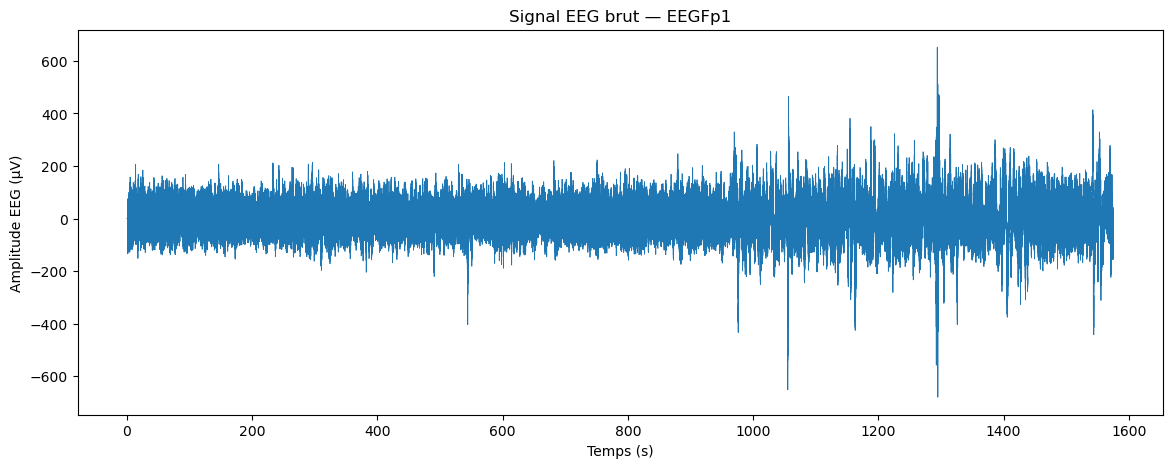

In [9]:
#visualisation 
canaux_eeg = [c for c in eeg.columns if c.startswith("EEG")]
canal = canaux_eeg[0]

plt.figure(figsize=(14,5))
plt.plot(eeg["Time"], eeg[canal], linewidth=0.6)
plt.xlabel("Temps (s)"); plt.ylabel("Amplitude EEG (µV)")
plt.title(f"Signal EEG brut — {canal}")
plt.show()
#avant tout modèle, on regarde toujours les données à l'œil — c'est la meilleure façon de repérer une anomalie (capteur défectueux, dérive du signal) et de se faire une première intuition sur ce à quoi ressemble une crise.

In [10]:


# 1. Lire le fichier Excel
chemin_xlsx = r"C:\Users\USER\Desktop\detection-crises-absence-eeg-main\data_csv\Annotations.xlsx"
# (ou l'endroit où se trouve réellement le fichier)

annot = pd.read_excel(chemin_xlsx)

# 2. Sauvegarder en CSV (dans le même dossier)
chemin_csv = r"C:\Users\USER\Desktop\detection-crises-absence-eeg-main\data_csv\Annotations.csv"
annot.to_csv(chemin_csv, index=False, encoding="utf-8")

print("✅ Fichier converti :", chemin_csv)

✅ Fichier converti : C:\Users\USER\Desktop\detection-crises-absence-eeg-main\data_csv\Annotations.csv


In [11]:
#Charger les annotations
annot = pd.read_csv(chemin_csv)
annot.head()
#le fichier EEG seul ne dit pas où sont les crises — c'est le fichier d'annotations qui porte cette information (vérité terrain). Sans lui, impossible de construire une variable cible.

C:\Users\USER\AppData\Local\Temp\ipykernel_19052\1862013602.py:2: DtypeWarning: Columns (0,1,4) have mixed types. Specify dtype option on import or set low_memory=False.
  annot = pd.read_csv(chemin_csv)


,Unnamed: 0,Sexe,Age,NombreCrises,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,...,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
0,190304A-E,M,17.0,1.0,NaN,0.441042,0.441123,NaN,NaN,NaN,...,NaN,NaN,NaN,0.432396,NaN,NaN,NaN,NaN,NaN,NaN
1,191113A-D,F,25.0,2.0,NaN,0.443900,0.444051,0.445914,0.445972,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,200625A-F,M,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210204B-C,F,5.0,6.0,NaN,0.431829,0.431887,0.433669,0.433727,0.436308,...,NaN,NaN,NaN,0.433796,0.433808,0.433819,0.434815,0.434873,0.438391,0.439398
4,210208B-G,F,14.0,4.0,NaN,0.471678,0.471794,0.472500,0.472581,0.475359,...,NaN,NaN,NaN,0.470359,0.470370,0.471412,0.471574,0.473403,0.473866,NaN


In [12]:
annot.head()
print(annot.columns.tolist())
print(annot.dtypes)

['Unnamed: 0', 'Sexe', 'Age', 'NombreCrises', 'TypeAbs', 'DebCE1', 'FinCE1', 'DebCE2', 'FinCE2', 'DebCE3', 'FinCE3', 'DebCE4', 'FinCE4', 'DebutCE5', 'FinCE5', 'DebCE6', 'FinCE6', 'DebCE7', 'FinCE7', 'DebCE8', 'FinCE8', 'DebCE9', 'FinCE9', 'DebCE10', 'FinCE10', 'DebtCE11', 'FinCE11', 'DebCE12', 'FinCE12', 'Intercrit1', 'Intercrit2', 'Intercrit3', 'Intercrit4', 'Intercrit5', 'Intercrit6', 'Intercrit7']
Unnamed: 0       object
Sexe             object
Age             float64
NombreCrises    float64
TypeAbs          object
DebCE1          float64
FinCE1          float64
DebCE2          float64
FinCE2          float64
DebCE3          float64
FinCE3          float64
DebCE4          float64
FinCE4          float64
DebutCE5        float64
FinCE5          float64
DebCE6          float64
FinCE6          float64
DebCE7          float64
FinCE7          float64
DebCE8          float64
FinCE8          float64
DebCE9          float64
FinCE9          float64
DebCE10         float64
FinCE10         floa

In [13]:
print("Colonnes :", annot.columns.tolist())
print("Forme    :", annot.shape)
annot.head()

Colonnes : ['Unnamed: 0', 'Sexe', 'Age', 'NombreCrises', 'TypeAbs', 'DebCE1', 'FinCE1', 'DebCE2', 'FinCE2', 'DebCE3', 'FinCE3', 'DebCE4', 'FinCE4', 'DebutCE5', 'FinCE5', 'DebCE6', 'FinCE6', 'DebCE7', 'FinCE7', 'DebCE8', 'FinCE8', 'DebCE9', 'FinCE9', 'DebCE10', 'FinCE10', 'DebtCE11', 'FinCE11', 'DebCE12', 'FinCE12', 'Intercrit1', 'Intercrit2', 'Intercrit3', 'Intercrit4', 'Intercrit5', 'Intercrit6', 'Intercrit7']
Forme    : (1048573, 36)


,Unnamed: 0,Sexe,Age,NombreCrises,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,...,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
0,190304A-E,M,17.0,1.0,NaN,0.441042,0.441123,NaN,NaN,NaN,...,NaN,NaN,NaN,0.432396,NaN,NaN,NaN,NaN,NaN,NaN
1,191113A-D,F,25.0,2.0,NaN,0.443900,0.444051,0.445914,0.445972,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,200625A-F,M,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210204B-C,F,5.0,6.0,NaN,0.431829,0.431887,0.433669,0.433727,0.436308,...,NaN,NaN,NaN,0.433796,0.433808,0.433819,0.434815,0.434873,0.438391,0.439398
4,210208B-G,F,14.0,4.0,NaN,0.471678,0.471794,0.472500,0.472581,0.475359,...,NaN,NaN,NaN,0.470359,0.470370,0.471412,0.471574,0.473403,0.473866,NaN


In [14]:
# Garder uniquement les lignes dont l'ID patient est rempli
annot_clean = annot[annot["Unnamed: 0"].notna()].copy()
annot_clean = annot_clean[
    annot_clean["Unnamed: 0"].astype(str).str.strip().ne("") &
    annot_clean["Unnamed: 0"].astype(str).str.strip().ne("nan")
].copy()

print("Patients restants :", len(annot_clean))
print("Forme             :", annot_clean.shape)
annot_clean.head()

Patients restants : 23
Forme             : (23, 36)


,Unnamed: 0,Sexe,Age,NombreCrises,TypeAbs,DebCE1,FinCE1,DebCE2,FinCE2,DebCE3,...,FinCE11,DebCE12,FinCE12,Intercrit1,Intercrit2,Intercrit3,Intercrit4,Intercrit5,Intercrit6,Intercrit7
0,190304A-E,M,17.0,1.0,NaN,0.441042,0.441123,NaN,NaN,NaN,...,NaN,NaN,NaN,0.432396,NaN,NaN,NaN,NaN,NaN,NaN
1,191113A-D,F,25.0,2.0,NaN,0.443900,0.444051,0.445914,0.445972,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,200625A-F,M,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,210204B-C,F,5.0,6.0,NaN,0.431829,0.431887,0.433669,0.433727,0.436308,...,NaN,NaN,NaN,0.433796,0.433808,0.433819,0.434815,0.434873,0.438391,0.439398
4,210208B-G,F,14.0,4.0,NaN,0.471678,0.471794,0.472500,0.472581,0.475359,...,NaN,NaN,NaN,0.470359,0.470370,0.471412,0.471574,0.473403,0.473866,NaN


In [15]:
ids = annot_clean["Unnamed: 0"].astype(str).tolist()
print(ids)

['190304A-E', '191113A-D', ' 200625A-F ', '210204B-C', '210208B-G', '210406A-F', '210427B-C', '210504B-C', '210914B-A', '210928B-B', '211027B-C', '211104B-D', '230406B-A', '230515B-G', '220106A-A', '220121B-D', '230102B-F', '230105B-H', '230210B-D', '230224B-B', '230515B-G', '230519A-E', '230718A-A']


In [16]:
import os

# Nom de ton fichier EEG chargé (adapte si besoin)
nom_eeg = "190304A_E_0000d.csv"   # ou celui que tu as chargé

# Extraire la partie avant "_0000"
prefixe = nom_eeg.split("_0000")[0]           # "190304A_E"
prefixe_tiret = prefixe.replace("_", "-")     # "190304A-E"

print("Préfixe EEG        :", prefixe)
print("ID attendu dans Excel :", prefixe_tiret)

# Vérifier qu'il existe bien dans annot_clean
if prefixe_tiret in ids:
    print("✅ ID trouvé dans le fichier d'annotations")
else:
    print("❌ ID non trouvé — voici les IDs proches :")
    proches = [i for i in ids if i.startswith(prefixe[:7])]
    print(proches)

Préfixe EEG        : 190304A_E
ID attendu dans Excel : 190304A-E
✅ ID trouvé dans le fichier d'annotations


In [17]:
id_patient = "190304A-E"   # remplace par celui trouvé en A3

ligne = annot_clean[annot_clean["Unnamed: 0"] == id_patient]
print("Lignes trouvées :", len(ligne))

# Afficher en colonnes pour bien voir
ligne.T

Lignes trouvées : 1


,0
Unnamed: 0,190304A-E
Sexe,M
Age,17.0
NombreCrises,1.0
TypeAbs,NaN
DebCE1,0.441042
FinCE1,0.441123
DebCE2,NaN
FinCE2,NaN
DebCE3,NaN


In [18]:
import re

paires = []
for i in range(1, 13):   # DebCE1 à DebCE12
    col_deb = None
    col_fin = None
    for c in annot_clean.columns:
        # Reconnaît DebCEi, DebutCEi, DebtCEi
        if re.fullmatch(rf"(Deb|Debut|Debt)CE{i}", c):
            col_deb = c
        if re.fullmatch(rf"FinCE{i}", c):
            col_fin = c

    if col_deb and col_fin:
        deb = ligne[col_deb].values[0]
        fin = ligne[col_fin].values[0]
        if pd.notna(deb) and pd.notna(fin):
            paires.append({
                "Crise": i,
                "Colonne_debut": col_deb,
                "Colonne_fin": col_fin,
                "Debut_brut": float(deb),
                "Fin_brut": float(fin),
            })

crises = pd.DataFrame(paires)
crises

,Crise,Colonne_debut,Colonne_fin,Debut_brut,Fin_brut
0,1,DebCE1,FinCE1,0.441042,0.441123


In [19]:
# Conversion des valeurs Excel en secondes absolues (depuis minuit)
SECONDES_PAR_JOUR = 86400

debut_absolu_s = crises["Debut_brut"].iloc[0] * SECONDES_PAR_JOUR
fin_absolu_s   = crises["Fin_brut"].iloc[0] * SECONDES_PAR_JOUR
duree_crise_s  = fin_absolu_s - debut_absolu_s

print(f"Début absolu  : {debut_absolu_s:.1f} s = {debut_absolu_s/3600:.2f} h")
print(f"Fin absolue   : {fin_absolu_s:.1f} s = {fin_absolu_s/3600:.2f} h")
print(f"Durée crise   : {duree_crise_s:.2f} s")

print()
print("Dans le signal EEG : Time va de", eeg["Time"].min(), "à", eeg["Time"].max())

Début absolu  : 38106.0 s = 10.59 h
Fin absolue   : 38113.0 s = 10.59 h
Durée crise   : 7.00 s

Dans le signal EEG : Time va de 0.0 à 1574.99609375


In [20]:
from matio import load_from_mat

chemin_mat = r"C:\Users\USER\Desktop\Projet data mining 3AINFO\190304A_E_0000d.mat"
data = load_from_mat(chemin_mat, raw_data=False, add_table_attrs=True)

for nom, table in data.items():
    print("Variable :", nom)
    if hasattr(table, "attrs"):
        print("Attributs :", table.attrs)

Variable : output_d
Attributs : {'varDescriptions': [], 'varUnits': [], 'varContinuity': [], 'UserData': array([], shape=(0, 0), dtype=float64), 'Description': ''}


In [21]:
from matio import load_from_mat

chemin_mat = r"C:\Users\USER\Desktop\Projet data mining 3AINFO\190304A_E_0000d.mat"
data = load_from_mat(chemin_mat, raw_data=False, add_table_attrs=True)

print("Variables disponibles :", list(data.keys()))
for nom, table in data.items():
    print(f"\n=== {nom} ===")
    print("Type :", type(table))
    if hasattr(table, "attrs"):
        print("Attributs :", table.attrs)

Variables disponibles : ['output_d']

=== output_d ===
Type : <class 'pandas.core.frame.DataFrame'>
Attributs : {'varDescriptions': [], 'varUnits': [], 'varContinuity': [], 'UserData': array([], shape=(0, 0), dtype=float64), 'Description': ''}


In [22]:
chemin_mat_h = r"C:\Users\USER\Desktop\Projet data mining 3AINFO\190304A_E_0000h.mat"
data_h = load_from_mat(chemin_mat_h, raw_data=False, add_table_attrs=True)

print("Variables disponibles :", list(data_h.keys()))
for nom, table in data_h.items():
    print(f"\n=== {nom} ===")
    if hasattr(table, "head"):
        print(table.head(15))
    if hasattr(table, "attrs"):
        print("Attributs :", table.attrs)
        

Variables disponibles : ['output_h']

=== output_h ===
                                                       Annotations Duration
Onset                                                                      
0 days 00:00:00                                             D��but      NaT
0 days 00:00:01  <IMPEDANCE> Fp1:22k Fp2:15k F7:31k F3:18k Fz:2...      NaT
0 days 00:03:58                                     HPN 6mn d��but      NaT
0 days 00:04:17                                     HPN - 00:00:20      NaT
0 days 00:04:37                                     HPN - 00:00:40      NaT
0 days 00:04:57                                     HPN - 00:01:00      NaT
0 days 00:05:17                                     HPN - 00:01:20      NaT
0 days 00:05:37                                     HPN - 00:01:40      NaT
0 days 00:05:57                                     HPN - 00:02:00      NaT
0 days 00:06:17                                     HPN - 00:02:20      NaT
0 days 00:06:26                  

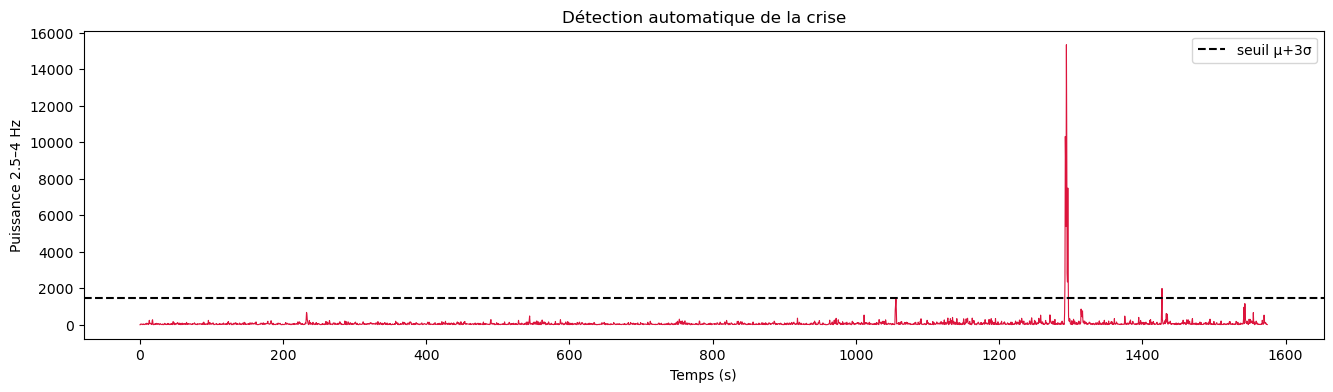

Pic maximal à t = 1294.00 s
Valeur du pic   : 1.535e+04
Seuil μ+3σ      : 1.448e+03
Ratio pic/seuil : 10.60


In [23]:
from scipy.signal import spectrogram
import numpy as np
import matplotlib.pyplot as plt

signal = eeg[canal].values

f_spec, t_spec, Sxx = spectrogram(signal, fs=fs, nperseg=int(fs), noverlap=int(fs*0.5))

# Bande typique des absences : 2.5 - 4 Hz
mask = (f_spec >= 2.5) & (f_spec <= 4)
puissance = Sxx[mask, :].sum(axis=0)

plt.figure(figsize=(16, 4))
plt.plot(t_spec, puissance, color="crimson", lw=0.8)
plt.axhline(puissance.mean() + 3*puissance.std(), color="k", ls="--", label="seuil μ+3σ")
plt.xlabel("Temps (s)")
plt.ylabel("Puissance 2.5–4 Hz")
plt.title("Détection automatique de la crise")
plt.legend()
plt.show()

idx_pic = np.argmax(puissance)
t_pic = t_spec[idx_pic]
print(f"Pic maximal à t = {t_pic:.2f} s")
print(f"Valeur du pic   : {puissance[idx_pic]:.3e}")
print(f"Seuil μ+3σ      : {puissance.mean() + 3*puissance.std():.3e}")
print(f"Ratio pic/seuil : {puissance[idx_pic] / (puissance.mean()+3*puissance.std()):.2f}")

In [24]:
#Calculer l'offset et convertir les crises

# Position de la crise dans l'EEG (détectée)
t_pic = 1294.0   # (valeur trouvée)

# Position absolue de la crise (Excel)
debut_absolu_crise = crises["Debut_brut"].iloc[0] * 86400

# Offset = heure de début de l'enregistrement
offset_s = debut_absolu_crise - t_pic

heures  = int(offset_s // 3600)
minutes = int((offset_s % 3600) // 60)
sec     = offset_s % 60

print(f"Offset (heure de début d'enregistrement) : {offset_s:.1f} s")
print(f"Soit : {heures:02d}h{minutes:02d}min{sec:05.2f}s")

# Conversion finale : crises en temps relatif au début de l'EEG
crises["Debut_s"] = crises["Debut_brut"] * 86400 - offset_s
crises["Fin_s"]   = crises["Fin_brut"]   * 86400 - offset_s
crises["Duree_s"] = crises["Fin_s"] - crises["Debut_s"]
print()
print(crises[["Crise", "Debut_s", "Fin_s", "Duree_s"]])

Offset (heure de début d'enregistrement) : 36812.0 s
Soit : 10h13min32.00s

   Crise  Debut_s   Fin_s  Duree_s
0      1   1294.0  1301.0      7.0


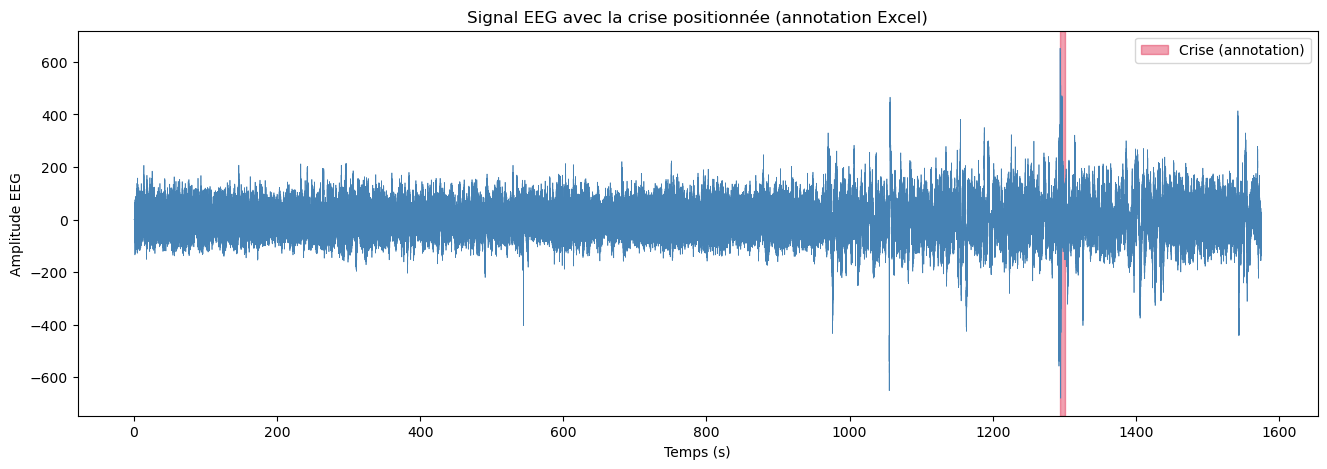

In [25]:
plt.figure(figsize=(16, 5))
plt.plot(eeg["Time"], eeg[canal], lw=0.5, color="steelblue")
for _, row in crises.iterrows():
    plt.axvspan(row["Debut_s"], row["Fin_s"], color="crimson", alpha=0.4,
                label="Crise (annotation)")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude EEG")
plt.title("Signal EEG avec la crise positionnée (annotation Excel)")
plt.legend()
plt.show()

In [26]:
# Variable cible

eeg["Class"] = 0
for _, row in crises.iterrows():
    mask = (eeg["Time"] >= row["Debut_s"]) & (eeg["Time"] <= row["Fin_s"])
    eeg.loc[mask, "Class"] = 1

print("Répartition :")
print(eeg["Class"].value_counts())
print()
print("Proportions (%):")
print((eeg["Class"].value_counts(normalize=True) * 100).round(3))

Répartition :
Class
0    401408
1      1792
Name: count, dtype: int64

Proportions (%):
Class
0    99.556
1     0.444
Name: proportion, dtype: float64


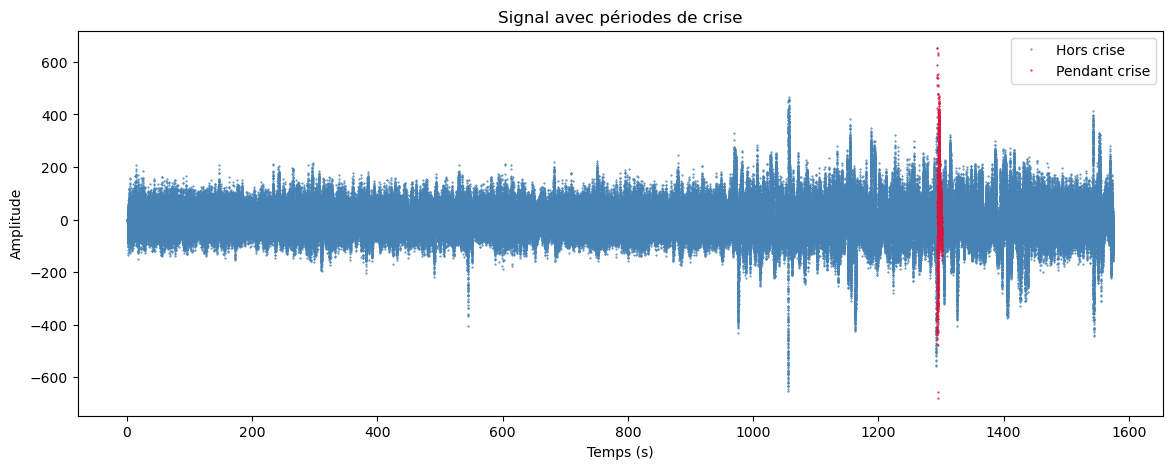

In [27]:
#Visualisation crise / hors crise
hors  = eeg[eeg["Class"] == 0]
crise = eeg[eeg["Class"] == 1]

plt.figure(figsize=(14, 5))
plt.plot(hors["Time"],  hors[canal],  '.', ms=1, color="steelblue", label="Hors crise")
plt.plot(crise["Time"], crise[canal], '.', ms=1, color="crimson",   label="Pendant crise")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.title("Signal avec périodes de crise")
plt.show()

In [28]:
#segmentation 
WINDOW_SEC = 2
OVERLAP    = 0.5

win_size = int(WINDOW_SEC * fs)
step     = int(win_size * (1 - OVERLAP))

windows_idx = []
i = 0
while i + win_size <= len(eeg):
    windows_idx.append((i, i + win_size))
    i += step

print(f"Taille fenêtre : {win_size} échantillons ({WINDOW_SEC} s)")
print(f"Pas            : {step} échantillons (recouvrement {OVERLAP*100:.0f}%)")
print(f"Nombre de fenêtres : {len(windows_idx)}")

Taille fenêtre : 512 échantillons (2 s)
Pas            : 256 échantillons (recouvrement 50%)
Nombre de fenêtres : 1574


In [30]:
#Features temporelles
def features_temporelles(signal):
    return {
        "Mean":      np.mean(signal),
        "Std":       np.std(signal),
        "Variance":  np.var(signal),
        "Min":       np.min(signal),
        "Max":       np.max(signal),
        "Amplitude": np.max(signal) - np.min(signal),
        "RMS":       np.sqrt(np.mean(signal**2)),
        "Energy":    np.sum(signal**2),
    }

In [31]:
#Features fréquentielles
from scipy.fft import rfft, rfftfreq

BANDS = {"Delta": (0.5, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30)}

def puissance_bandes(signal, fs):
    n = len(signal)
    fft_vals = np.abs(rfft(signal)) ** 2
    freqs = rfftfreq(n, d=1/fs)
    return {
        f"Power_{b}": fft_vals[(freqs >= lo) & (freqs < hi)].sum()
        for b, (lo, hi) in BANDS.items()
    }

In [32]:
#construction de dataset
rows = []
for w_id, (start, end) in enumerate(windows_idx, start=1):
    seg = eeg.iloc[start:end]
    signal = seg[canal].values

    row = {"Window": w_id}
    row.update(features_temporelles(signal))
    row.update(puissance_bandes(signal, fs))
    row["Class"] = int(seg["Class"].mean() >= 0.5)
    row["Window_start_s"] = seg["Time"].iloc[0]
    row["Window_end_s"]   = seg["Time"].iloc[-1]
    rows.append(row)

dataset = pd.DataFrame(rows)
print(f"Total fenêtres : {len(dataset)}")
print(f"Classe 0 : {(dataset.Class==0).sum()}")
print(f"Classe 1 : {(dataset.Class==1).sum()}")
dataset.head()

Total fenêtres : 1574
Classe 0 : 1566
Classe 1 : 8


,Window,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Power_Delta,Power_Theta,Power_Alpha,Power_Beta,Class,Window_start_s,Window_end_s
0,1,-6.503391,23.634193,558.575075,-134.552300,75.341588,209.893889,24.512633,3.076450e+05,1.255536e+07,4.653548e+06,1.113699e+07,5.999690e+06,0,0.0,1.996094
1,2,-17.829022,36.628569,1341.652099,-134.552300,88.508080,223.060380,40.737282,8.496774e+05,1.540329e+07,1.112275e+07,3.542214e+07,1.452050e+07,0,1.0,2.996094
2,3,-11.051178,42.031940,1766.683978,-127.853559,99.903639,227.757198,43.460471,9.670720e+05,3.028962e+07,1.189882e+07,5.079887e+07,1.612753e+07,0,2.0,3.996094
3,4,-0.637632,46.488824,2161.210716,-128.238544,137.786175,266.024720,46.493196,1.106748e+06,1.105754e+07,8.293517e+06,1.211766e+08,1.899077e+07,0,3.0,4.996094
4,5,3.385914,49.974440,2497.444700,-128.238544,157.959396,286.197940,50.089012,1.284561e+06,1.546856e+07,2.517370e+07,1.348820e+08,2.790123e+07,0,4.0,5.996094


In [33]:
#Comparaison des moyennes par classe
feature_cols = ["Mean","Std","Variance","Min","Max","Amplitude","RMS","Energy",
                "Power_Delta","Power_Theta","Power_Alpha","Power_Beta"]

comparaison = dataset.groupby("Class")[feature_cols].mean().T
comparaison.columns = ["Classe 0 (pas crise)", "Classe 1 (crise)"]
comparaison

,Classe 0 (pas crise),Classe 1 (crise)
Mean,3.125286e-02,3.265219e+01
Std,5.360429e+01,1.346029e+02
Variance,3.226595e+03,2.349902e+04
Min,-1.303079e+02,-3.109044e+02
Max,1.426149e+02,3.992873e+02
Amplitude,2.729227e+02,7.101917e+02
RMS,5.979873e+01,1.577387e+02
Energy,2.186532e+06,1.618498e+07
Power_Delta,1.666634e+08,2.047539e+09
Power_Theta,1.899484e+07,3.291463e+08


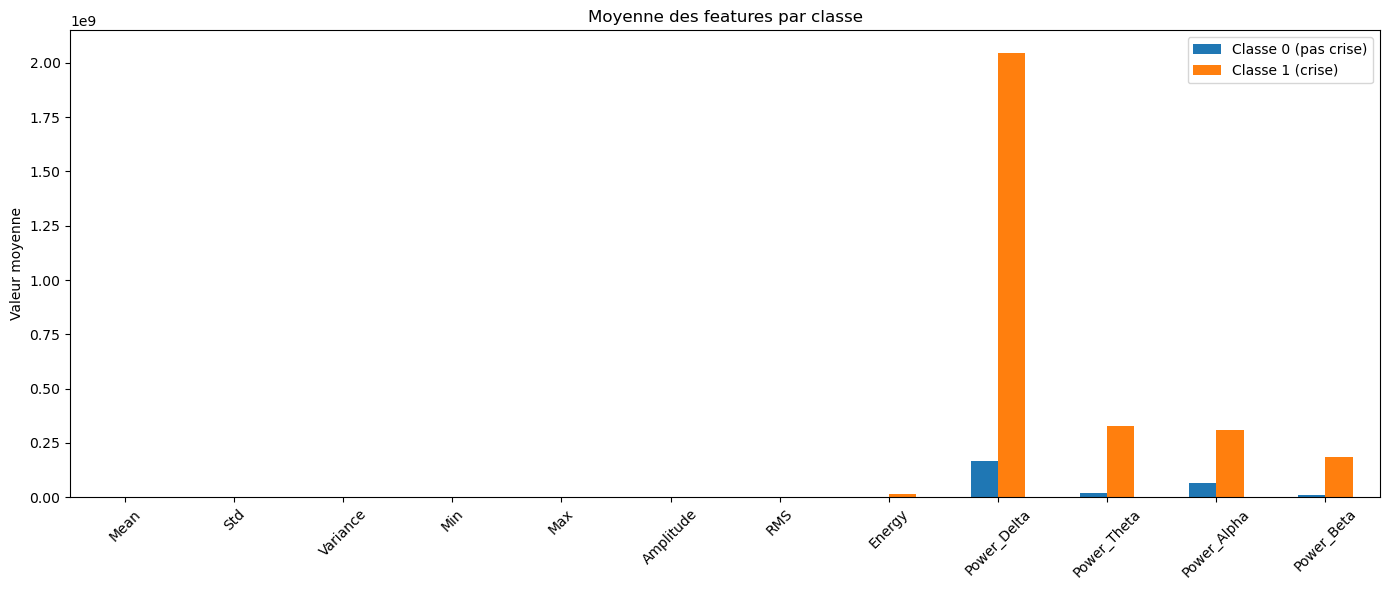

In [34]:
comparaison.plot(kind="bar", figsize=(14, 6),
                 title="Moyenne des features par classe")
plt.ylabel("Valeur moyenne")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

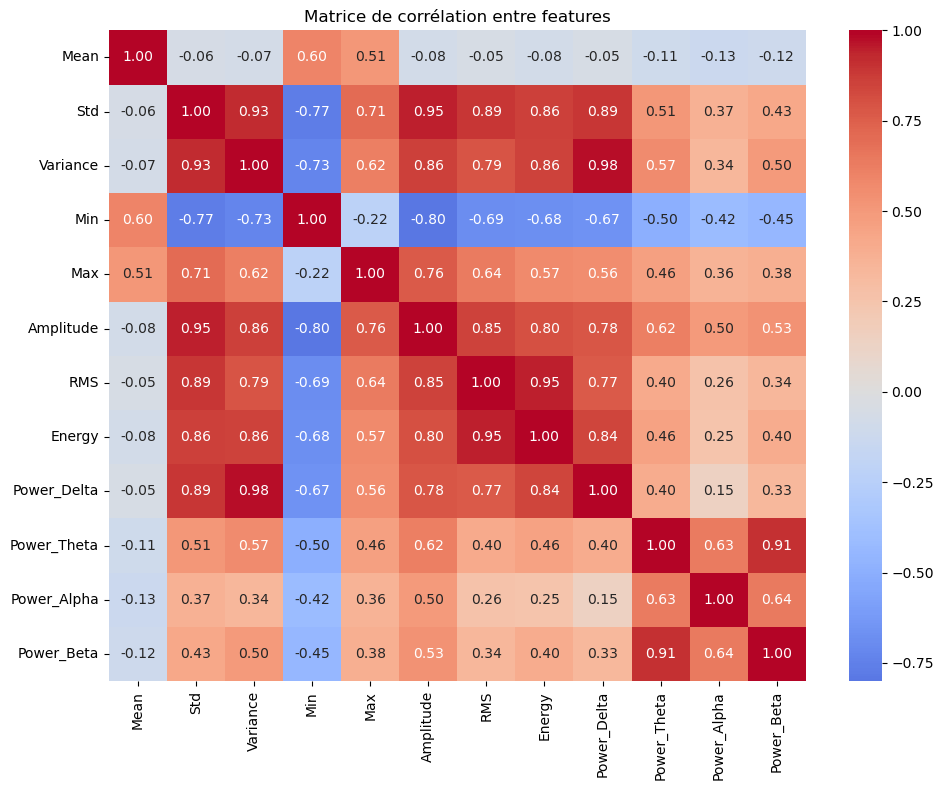

In [35]:
import seaborn as sns

corr = dataset[feature_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation entre features")
plt.tight_layout()
plt.show()

In [36]:
#Split train/test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = dataset[feature_cols]
y = dataset["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train : {X_train.shape[0]} fenêtres — classe 1 : {y_train.mean()*100:.2f}%")
print(f"Test  : {X_test.shape[0]} fenêtres — classe 1 : {y_test.mean()*100:.2f}%")

Train : 1259 fenêtres — classe 1 : 0.48%
Test  : 315 fenêtres — classe 1 : 0.63%


In [37]:
#modeles et evaluation
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay)

models = {
    "Decision Tree": (DecisionTreeClassifier(random_state=42), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), X_train, X_test),
    "KNN":           (KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled),
    "SVM":           (SVC(kernel="rbf", random_state=42), X_train_scaled, X_test_scaled),
}

results, predictions = [], {}
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    predictions[name] = y_pred
    results.append({
        "Modele":    name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred, zero_division=0),
        "F1-score":  f1_score(y_test, y_pred, zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Modele").round(3)
results_df

,Accuracy,Precision,Recall,F1-score
Modele,,,,
Decision Tree,0.997,0.667,1.0,0.8
Random Forest,0.994,0.000,0.0,0.0
KNN,0.994,0.000,0.0,0.0
SVM,0.994,0.000,0.0,0.0


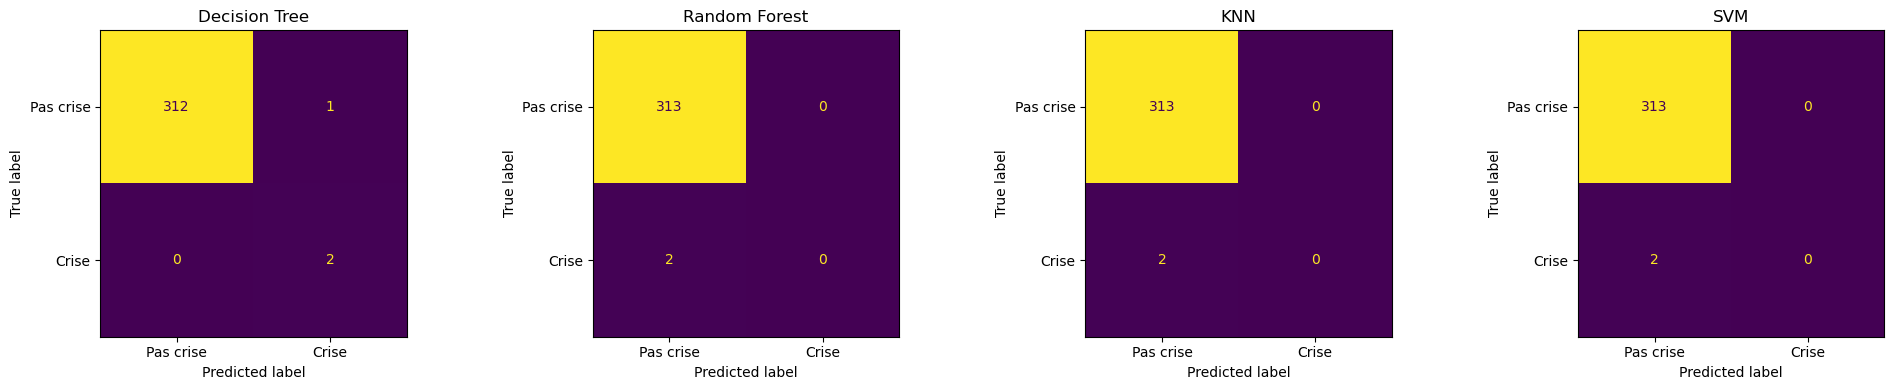

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, yp) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, yp)
    ConfusionMatrixDisplay(cm, display_labels=["Pas crise","Crise"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()